# Data preprocessing

**Purpose:** Load the HDF5 maps of all 1,450 ROIs in 17 cities, stack the seven
input channels and the R1B1 target, split by ROI (70/15/15, seed 42), normalise,
and save the arrays with the split metadata.

**Run this notebook once.**

---

## Pipeline overview

```
Cell 1  — Imports & Drive mount
Cell 2  — Configuration constants
Cell 3  — HDF5 loader functions
Cell 4  — Load all ROIs from the JSON file list
Cell 5  — Add channel dim, stack 7-channel tensor, 70/15/15 split
Cell 6  — Normalisation functions + apply to all splits
Cell 7  — Signal strength histogram diagnostic
Cell 8  — Sanity check: spatial alignment (TX vs R0B0)
Cell 9  — Build split metadata (city/ROI/TX per sample)
Cell 10 — Save arrays + metadata + config to Drive
Cell 11 — Verification: reload and confirm integrity
```

---

## Channel order (7 channels)

| ch | Name | Values | Notes |
|----|------|--------|-------|
| 0 | TX location | {0, 1} binary | Where the transmitter is |
| 1 | Building height | float32, metres | 0 = no building |
| 2 | R0B0 | dBm, normalised | Free-space, no buildings |
| 3 | R0B1 | dBm, normalised | Buildings, no reflection |
| 4 | R1B0 | dBm, normalised | Reflection, no buildings |
| 5 | Cos(θ) | [−1, 1] | Direction TX → pixel |
| 6 | Sin(θ) | [−1, 1] | Direction TX → pixel |

**Target:** R1B1 — 1 reflection + buildings (normalised [0, 1])

---

## Key design decisions

- **Split before normalise** — prevents data leakage from val/test into training stats
- **Fixed physical bounds [−120, 0] dBm** — the same normalisation for every sample and set
- **TX channel is binary** — all TXs are at fixed 60m altitude so height carries no information; only location varies
- **One building map per ROI** — buildings_h5 holds one `building_matrix` dataset per ROI (not per TX); tiled to (N_tx, 100, 100)
- **−120 dBm sentinel** — MATLAB replaces −∞ (completely blocked pixels) with −120 dBm


## Cell 1 — Imports & Drive Mount

In [ ]:
import os
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'

import json
import numpy as np
import h5py
import matplotlib.pyplot as plt
import pandas as pd
import gc
import time
from sklearn.model_selection import train_test_split
from google.colab import drive

drive.mount('/content/drive')
print('Drive mounted.')
print(f'numpy: {np.__version__}')

Mounted at /content/drive
Drive mounted.
numpy: 2.0.2


## Cell 2 — Configuration

In [ ]:
# ── Paths ─────────────────────────────────────────────────────────────────
META_JSON = '<DRIVE_DIR>/dataset_meta_res100.json'
SAVE_DIR  = '<DRIVE_DIR>/preprocessed'
os.makedirs(SAVE_DIR, exist_ok=True)

ALL_KEYS = ['buildings_h5', 'tx_loc_h5', 'sincos_h5',
            'r0b0_h5', 'r0b1_h5', 'r1b0_h5', 'r1b1_h5']

# ── Grid ──────────────────────────────────────────────────────────────────
GRID_H, GRID_W = 100, 100
N_CHANNELS     = 7
TX_PER_ROI     = 50

# ── Normalisation bounds (fixed) ─
PHYS_MIN   = -120.0   # dBm  — also the MATLAB sentinel for blocked pixels
PHYS_MAX   =    0.0   # dBm
RANGE_DBM  =  120.0
MAX_HEIGHT =   60.0   # metres — UAV altitude; building heights are clipped
                       # at 60 m and divided by 60.

# ── Split ratios ──────────────────────────────────────────────────────────
TEST_SIZE   = 0.15
VAL_SIZE    = 0.15 / 0.85   # 15% of full dataset from remaining 85%
RANDOM_SEED = 42

print('Configuration loaded.')
print(f'  Grid:          {GRID_H}x{GRID_W}')
print(f'  Channels:      {N_CHANNELS}')
print(f'  Norm range:    [{PHYS_MIN}, {PHYS_MAX}] dBm')
print(f'  Height ceil:   {MAX_HEIGHT} m  (UAV altitude)')
print(f'  Split:         70 / 15 / 15  (seed={RANDOM_SEED})')
print(f'  Save dir:      {SAVE_DIR}')


Configuration loaded.
  Grid:          100x100
  Channels:      7
  Norm range:    [-120.0, 0.0] dBm
  Height ceil:   60.0 m  (UAV altitude)
  Split:         70 / 15 / 15  (seed=42)
  Save dir:      <DRIVE_DIR>/preprocessed


## Cell 3 — HDF5 Loader Functions

**Key format notes:**
- `tx_loc_h5` and coverage maps: per-TX keys `Tx_1 … Tx_50` — sorted numerically
- `buildings_h5`: single key `building_matrix` (one map per ROI, tiled to N_tx)
- `sincos_h5`: keys `Cos_1/Sin_1 … Cos_50/Sin_50` — loaded by explicit integer index

**Orientation:** all maps are used as stored in the HDF5 files, without transpose.
Cell 8 checks the alignment of the TX channel with R0B0.

In [ ]:
def _load_tx_keyed_h5(path, transpose=False):
    """
    Load HDF5 with per-TX keys Tx_1...Tx_N.
    Returns (N, H, W) float32, sorted numerically.
    transpose=True: apply .T to each (H,W) matrix before stacking.
    """
    with h5py.File(path, 'r') as f:
        keys = sorted(f.keys(), key=lambda k: int(k.split('_')[1]))
        matrices = [f[k][:].T if transpose else f[k][:] for k in keys]
        return np.stack(matrices, axis=0).astype(np.float32)


def _load_buildings_h5(path, n_tx, transpose=False):
    """
    Load buildings_h5 written by v0.4 pipeline.
    Contains a SINGLE dataset 'building_matrix' (H, W) — one map per ROI.
    Tiles it n_tx times to produce (n_tx, H, W).
    """
    with h5py.File(path, 'r') as f:
        mat = f['building_matrix'][:].astype(np.float32)   # (H, W)
    if transpose:
        mat = mat.T
    return np.stack([mat] * n_tx, axis=0)   # (n_tx, H, W)


def _load_sincos_h5(path):
    """
    Load CosSin HDF5 with keys Cos_1/Sin_1...Cos_N/Sin_N.
    Uses explicit integer indexing — immune to alphabetical sort issues.
    Returns (N, H, W, 2) float32.
    """
    with h5py.File(path, 'r') as f:
        n = len([k for k in f.keys() if k.startswith('Cos_')])
        cos_arr = np.stack(
            [f[f'Cos_{i}'][:] for i in range(1, n + 1)], axis=0
        ).astype(np.float32)
        sin_arr = np.stack(
            [f[f'Sin_{i}'][:] for i in range(1, n + 1)], axis=0
        ).astype(np.float32)
    return np.stack([cos_arr, sin_arr], axis=-1)   # (N, H, W, 2)


def load_roi_from_paths(roi_paths):
    """
    Load one ROI from its 7 HDF5 file paths.

    Returns:
        TX     (N, 100, 100) — binary TX location mask {0, 1}
        BLD    (N, 100, 100) — building heights in metres (0 = no building)
        R0B0   (N, 100, 100) — free-space coverage map, dBm
        R0B1   (N, 100, 100) — buildings+no-reflection coverage map, dBm
        R1B0   (N, 100, 100) — reflection+no-buildings coverage map, dBm
        Y      (N, 100, 100) — target R1B1, dBm
        CosSin (N, 100, 100, 2) — [Cos(theta), Sin(theta)]

    TX and BLD are loaded as stored (no transpose).
    """
    TX     = _load_tx_keyed_h5(roi_paths['tx_loc_h5'])
    n_tx   = TX.shape[0]
    BLD    = _load_buildings_h5(roi_paths['buildings_h5'], n_tx)
    R0B0   = _load_tx_keyed_h5(roi_paths['r0b0_h5'])
    R0B1   = _load_tx_keyed_h5(roi_paths['r0b1_h5'])
    R1B0   = _load_tx_keyed_h5(roi_paths['r1b0_h5'])
    Y      = _load_tx_keyed_h5(roi_paths['r1b1_h5'])
    CosSin = _load_sincos_h5(roi_paths['sincos_h5'])

    assert TX.shape[0] == R0B0.shape[0] == CosSin.shape[0], \
        f'Sample count mismatch: TX={TX.shape[0]}, R0B0={R0B0.shape[0]}'
    assert TX.shape[1:] == (100, 100), \
        f'Unexpected spatial shape: {TX.shape[1:]}'
    return TX, BLD, R0B0, R0B1, R1B0, Y, CosSin


print('Loader functions defined.')
print('  _load_tx_keyed_h5  — for tx_loc, r0b0, r0b1, r1b0, r1b1')
print('  _load_buildings_h5 — for buildings (single matrix, tiled)')
print('  _load_sincos_h5    — for Cos/Sin (explicit integer index)')

Loader functions defined.
  _load_tx_keyed_h5  — for tx_loc, r0b0, r0b1, r1b0, r1b1
  _load_buildings_h5 — for buildings (single matrix, tiled)
  _load_sincos_h5    — for Cos/Sin (explicit integer index)


## Cell 4 — Load All ROIs

Iterates over all 1,450 ROIs across 17 cities. Three guards per ROI:
1. None-guard: skip if any JSON path is None
2. Disk-guard: skip if any file is missing on disk
3. Exception catch: skip and log if loading raises

This is a one-time step; Cell 10 saves the outputs.

In [ ]:
with open(META_JSON, 'r') as f:
    meta = json.load(f)
cities = meta['cities']

print(f'Cities ({len(cities)}): {list(cities.keys())}')
print(f'Total ROIs in JSON: {sum(len(cities[c]["rois"]) for c in cities)}')
print()

all_TX, all_BLD = [], []
all_R0B0, all_R0B1, all_R1B0 = [], [], []
all_Y, all_CosSin = [], []
all_meta_records = []   # ← track roi_id + original tx_idx at load time

skipped_none = skipped_missing = skipped_error = loaded = 0
t_start = time.time()

for city_name, city_data in cities.items():
    city_count = 0
    for roi_id, roi_paths in city_data['rois'].items():

        # Guard 1: None paths in JSON
        if any(v is None for v in roi_paths.values()):
            skipped_none += 1
            continue

        # Guard 2: Missing files on disk
        missing = [k for k in ALL_KEYS if not os.path.exists(roi_paths[k])]
        if missing:
            skipped_missing += 1
            continue

        # Load
        try:
            TX, BLD, R0B0, R0B1, R1B0, Y, CosSin = load_roi_from_paths(roi_paths)
            n_loaded_tx = TX.shape[0]
            all_TX.append(TX);     all_BLD.append(BLD)
            all_R0B0.append(R0B0); all_R0B1.append(R0B1)
            all_R1B0.append(R1B0); all_Y.append(Y)
            all_CosSin.append(CosSin)
            # Record metadata: one row per TX sample, preserving original tx key
            for tx_idx in range(1, n_loaded_tx + 1):
                all_meta_records.append({
                    'city':   city_name,
                    'roi_id': roi_id,
                    'tx_idx': tx_idx,   # original Tx_1...Tx_N key index
                })
            city_count += 1; loaded += 1
        except Exception as e:
            print(f'  [ERROR] {city_name}/{roi_id}: {e}')
            skipped_error += 1

    elapsed = (time.time() - t_start) / 60
    print(f'  {city_name}: {city_count} ROIs  ({elapsed:.0f} min elapsed)')

# Concatenate
TX     = np.concatenate(all_TX,     axis=0)
BLD    = np.concatenate(all_BLD,    axis=0)
R0B0   = np.concatenate(all_R0B0,   axis=0)
R0B1   = np.concatenate(all_R0B1,   axis=0)
R1B0   = np.concatenate(all_R1B0,   axis=0)
Y      = np.concatenate(all_Y,      axis=0)
CosSin = np.concatenate(all_CosSin, axis=0)
del all_TX, all_BLD, all_R0B0, all_R0B1, all_R1B0, all_Y, all_CosSin
gc.collect()

total_elapsed = (time.time() - t_start) / 60
print(f'\n{"+"*55}')
print(f'  Loaded:          {loaded:>6} ROIs')
print(f'  Skipped (None):  {skipped_none:>6}')
print(f'  Skipped (disk):  {skipped_missing:>6}')
print(f'  Skipped (error): {skipped_error:>6}')
print(f'  Total samples:   {TX.shape[0]:>6,}')
print(f'  TX shape:        {TX.shape}')
print(f'  CosSin shape:    {CosSin.shape}')
print(f'  Meta records:    {len(all_meta_records):>6,}  (should match TX.shape[0])')
assert len(all_meta_records) == TX.shape[0], \
    f'Meta record count {len(all_meta_records)} != TX samples {TX.shape[0]}'
print(f'  Total time:      {total_elapsed:.0f} min')
print(f'{"+"*55}')


Cities (17): ['Abu Dhabi', 'Bangkok', 'Beijing', 'Busan', 'Changsha', 'Chicago', 'Dalian', 'Doha', 'Dubai', 'Guangzhou', 'Hangzhou', 'Hefei', 'Hong Kong', 'Houston', 'Incheon', 'Istanbul', 'Jakarta']
Total ROIs in JSON: 1450

  Abu Dhabi: 39 ROIs  (6 min elapsed)
  Bangkok: 111 ROIs  (23 min elapsed)
  Beijing: 103 ROIs  (39 min elapsed)
  Busan: 219 ROIs  (73 min elapsed)
  Changsha: 43 ROIs  (80 min elapsed)
  Chicago: 63 ROIs  (90 min elapsed)
  Dalian: 23 ROIs  (94 min elapsed)
  Doha: 25 ROIs  (98 min elapsed)
  Dubai: 68 ROIs  (109 min elapsed)
  Guangzhou: 206 ROIs  (143 min elapsed)
  Hangzhou: 119 ROIs  (161 min elapsed)
  Hefei: 44 ROIs  (169 min elapsed)
  Hong Kong: 63 ROIs  (179 min elapsed)
  Houston: 47 ROIs  (186 min elapsed)
  Incheon: 152 ROIs  (210 min elapsed)
  Istanbul: 74 ROIs  (222 min elapsed)
  Jakarta: 51 ROIs  (231 min elapsed)

+++++++++++++++++++++++++++++++++++++++++++++++++++++++
  Loaded:            1450 ROIs
  Skipped (None):       0
  Skipped (disk): 

## Cell 5 — Stack & 70/15/15 Split

**Split order:** split is performed on RAW un-normalised data to prevent leakage.
Normalisation is applied in Cell 6 after the split.

In [ ]:
# ── Add channel dimension to single-channel arrays ─────────────────────────
TX   = TX[...,   np.newaxis]   # (N, 100, 100, 1)
BLD  = BLD[...,  np.newaxis]
R0B0 = R0B0[..., np.newaxis]
R0B1 = R0B1[..., np.newaxis]
R1B0 = R1B0[..., np.newaxis]
Y    = Y[...,    np.newaxis]
# CosSin already (N, 100, 100, 2)

# ── Stack into 7-channel tensor ────────────────────────────────────────────
# Channel order: [TX(0), BLD(1), R0B0(2), R0B1(3), R1B0(4), Cos(5), Sin(6)]
X_raw = np.concatenate([TX, BLD, R0B0, R0B1, R1B0, CosSin], axis=-1)
# Shape: (N, 100, 100, 7)


del TX, BLD, R0B0, R0B1, R1B0, CosSin
gc.collect()

print(f'X_raw shape: {X_raw.shape}   dtype: {X_raw.dtype}')
print(f'Y shape:     {Y.shape}')
print(f'Channel map: TX(0) | BLD(1) | R0B0(2) | R0B1(3) | R1B0(4) | Cos(5) | Sin(6)')

# ── 70/15/15 split on RAW data ─────────────────────────────────────────────
X_tr_val, X_test, Y_tr_val, Y_test = train_test_split(
    X_raw, Y, test_size=TEST_SIZE, random_state=RANDOM_SEED
)
X_tr, X_val, Y_tr, Y_val = train_test_split(
    X_tr_val, Y_tr_val, test_size=VAL_SIZE, random_state=RANDOM_SEED
)
del X_raw, X_tr_val, Y_tr_val
gc.collect()

n_total = X_tr.shape[0] + X_val.shape[0] + X_test.shape[0]
print(f'\nSplit (seed={RANDOM_SEED}):')
print(f'  Train: {X_tr.shape[0]:>7,}  ({X_tr.shape[0]/n_total*100:.1f}%)')
print(f'  Val:   {X_val.shape[0]:>7,}  ({X_val.shape[0]/n_total*100:.1f}%)')
print(f'  Test:  {X_test.shape[0]:>7,}  ({X_test.shape[0]/n_total*100:.1f}%)  <- held out')

## Cell 6 — Normalisation

Applied **after** the split — no data leakage.

| Channel | Method | Output range |
|---------|--------|--------------|
| TX (0) | Identity — already {0,1} | {0.0, 1.0} |
| BLD (1) | height / MAX_HEIGHT | [0, 1] |
| R0B0, R0B1, R1B0 (2–4) | (x + 120) / 120 | [0, 1] |
| Cos, Sin (5–6) | Identity — already [−1, 1] | [−1, 1] |
| Target R1B1 | (x + 120) / 120 | [0, 1] |

**Denormalise:** `value_dBm = value_norm × 120 − 120`

Note: −120 dBm pixels (MATLAB sentinel for blocked pixels) normalise to 0.0,
which is the correct representation — they map to the noise floor boundary.

In [ ]:
def norm_cov(arr):
    """Coverage maps (dBm) → [0, 1] using fixed physical bounds."""
    arr = arr.copy().astype(np.float32)
    arr[~np.isfinite(arr)] = PHYS_MIN
    arr = np.clip(arr, PHYS_MIN, PHYS_MAX)
    return (arr - PHYS_MIN) / RANGE_DBM


def norm_buildings(arr):
    """Building heights (metres) → [0, 1] via fixed ceiling."""
    arr = arr.copy().astype(np.float32)
    arr = np.clip(arr, 0.0, MAX_HEIGHT)
    return arr / MAX_HEIGHT


def normalize_split(X_split, Y_split):
    """Apply per-channel normalisation to one split."""
    X_out = np.empty_like(X_split, dtype=np.float32)
    X_out[..., 0] = X_split[..., 0].astype(np.float32)   # TX — pass through
    X_out[..., 1] = norm_buildings(X_split[..., 1])       # BLD heights
    X_out[..., 2] = norm_cov(X_split[..., 2])             # R0B0
    X_out[..., 3] = norm_cov(X_split[..., 3])             # R0B1
    X_out[..., 4] = norm_cov(X_split[..., 4])             # R1B0
    X_out[..., 5] = X_split[..., 5].astype(np.float32)   # Cos — pass through
    X_out[..., 6] = X_split[..., 6].astype(np.float32)   # Sin — pass through
    Y_out = norm_cov(Y_split)
    return X_out, Y_out


def to_dbm(arr_norm):
    """Normalised [0, 1] → dBm."""
    return arr_norm * RANGE_DBM + PHYS_MIN


# ── Building height diagnostic ─────────────────────────────────────────────
bld_max = X_tr[..., 1].max()
bld_nonzero_mean = X_tr[X_tr[..., 1] > 0, 1].mean() if (X_tr[..., 1] > 0).any() else 0
print(f'Building height (raw, train set):')
print(f'  Max:              {bld_max:.1f} m  (ceiling = {MAX_HEIGHT:.0f} m)')
print(f'  Mean (non-zero):  {bld_nonzero_mean:.1f} m')
if bld_max < MAX_HEIGHT * 0.4:
    print(f'  WARNING: actual max ({bld_max:.0f}m) far below ceiling ({MAX_HEIGHT:.0f}m).')
    print(f'  Consider updating MAX_HEIGHT to {int(bld_max * 1.2)}m.')
else:
    print(f'  MAX_HEIGHT={MAX_HEIGHT:.0f}m is appropriate.')

# ── Normalise all splits ───────────────────────────────────────────────────
print('\nNormalising splits...')
X_tr_norm,   Y_tr_norm   = normalize_split(X_tr,   Y_tr)
X_val_norm,  Y_val_norm  = normalize_split(X_val,  Y_val)
X_test_norm, Y_test_norm = normalize_split(X_test, Y_test)

del X_tr, Y_tr, X_val, Y_val, X_test, Y_test
gc.collect()

print(f'X_tr_norm  range: [{X_tr_norm.min():.4f}, {X_tr_norm.max():.4f}]  shape: {X_tr_norm.shape}')
print(f'Y_tr_norm  range: [{Y_tr_norm.min():.4f}, {Y_tr_norm.max():.4f}]')
print(f'\nDenormalise formula: value_dBm = value_norm x {RANGE_DBM:.0f} + ({PHYS_MIN:.0f})')

## Cell 7 — Signal Strength Histogram Diagnostic

Inspect the distribution of R1B1 values in the training set.

**Why this matters:**
- The spike at −120 dBm (normalised 0.0) represents pixels where MATLAB replaced −∞
  (completely blocked) with the sentinel value. These are physically distinct from pixels
  with weak but real signal.
- The sentinel fraction directly affects loss function behaviour: a high fraction means
  most training signal comes from trivially predicting the noise floor, not propagation.
- The threshold table helps assess whether masking sentinel pixels from the loss
  would materially change training dynamics.
- The zoomed panel reveals whether MATLAB ever writes near-sentinel values (e.g. −119 dBm)
  as real physics — a gap between the spike and the bulk distribution confirms a clean
  sentinel/signal boundary.


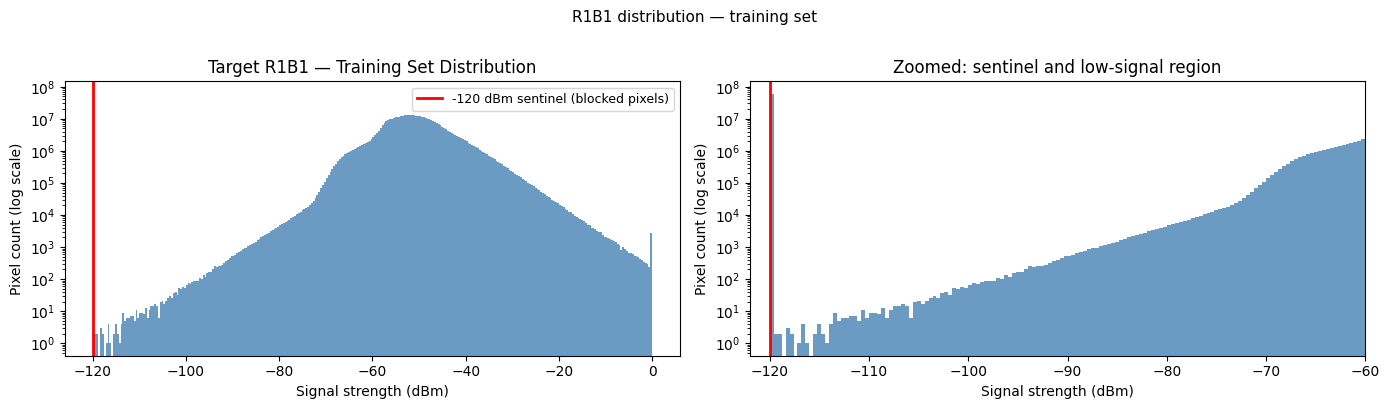

Sentinel pixels (= -120 dBm):  11.8% of training pixels
Real signal pixels (> -120):   88.2%

Fraction below candidate thresholds:
  -119 dBm  (norm=0.008):  11.85%
  -115 dBm  (norm=0.042):  11.85%
  -110 dBm  (norm=0.083):  11.85%
  -100 dBm  (norm=0.167):  11.85%
   -90 dBm  (norm=0.250):  11.85%
   -80 dBm  (norm=0.333):  11.86%


In [ ]:
Y_flat_dbm = Y_tr_norm.flatten() * RANGE_DBM + PHYS_MIN

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Full range
axes[0].hist(Y_flat_dbm, bins=300, log=True, color='steelblue', alpha=0.8)
axes[0].axvline(x=-120, color='red', lw=2, label='-120 dBm sentinel (blocked pixels)')
axes[0].set_xlabel('Signal strength (dBm)')
axes[0].set_ylabel('Pixel count (log scale)')
axes[0].set_title('Target R1B1 — Training Set Distribution')
axes[0].legend(fontsize=9)

# Zoomed: noise floor region
axes[1].hist(Y_flat_dbm, bins=300, log=True, color='steelblue', alpha=0.8)
axes[1].axvline(x=-120, color='red', lw=2)
axes[1].set_xlim(-122, -60)
axes[1].set_xlabel('Signal strength (dBm)')
axes[1].set_ylabel('Pixel count (log scale)')
axes[1].set_title('Zoomed: sentinel and low-signal region')

plt.suptitle('R1B1 distribution — training set', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

# Fraction at sentinel vs real signal
sentinel_frac = (Y_flat_dbm <= -119.9).mean()
print(f'Sentinel pixels (= -120 dBm):  {sentinel_frac*100:.1f}% of training pixels')
print(f'Real signal pixels (> -120):   {(1-sentinel_frac)*100:.1f}%')
print()
print('Fraction below candidate thresholds:')
for t in [-119, -115, -110, -100, -90, -80]:
    frac = (Y_flat_dbm < t).mean()
    tn   = (t - PHYS_MIN) / RANGE_DBM
    print(f'  {t:4d} dBm  (norm={tn:.3f}):  {frac*100:.2f}%')

## Cell 8 — Sanity Check: Spatial Alignment

Verify that the TX marker in ch0 sits inside the high-signal region of R0B0.
If the ★ marker appears in a dark region, the channels are misaligned.

**Six panels shown:**
- ch0 TX — binary transmitter location mask
- ch1 BLD — building heights (normalised to UAV altitude ceiling = 60 m)
- ch2 R0B0 — free-space (no buildings, no reflections) — should be bright at TX
- ch3 R0B1 — buildings, no reflection — shadows should match ch1 building locations
- ch4 R1B0 — reflection, no buildings — should show reflection bright spots
- Target R1B1 — full ray-traced output (buildings + 1 reflection)

**Expected alignment:** TX star falls inside the bright R0B0 region.
R0B1 darker than R0B0 in building-shadow zones. R1B0 brighter than R0B0 in reflection zones.


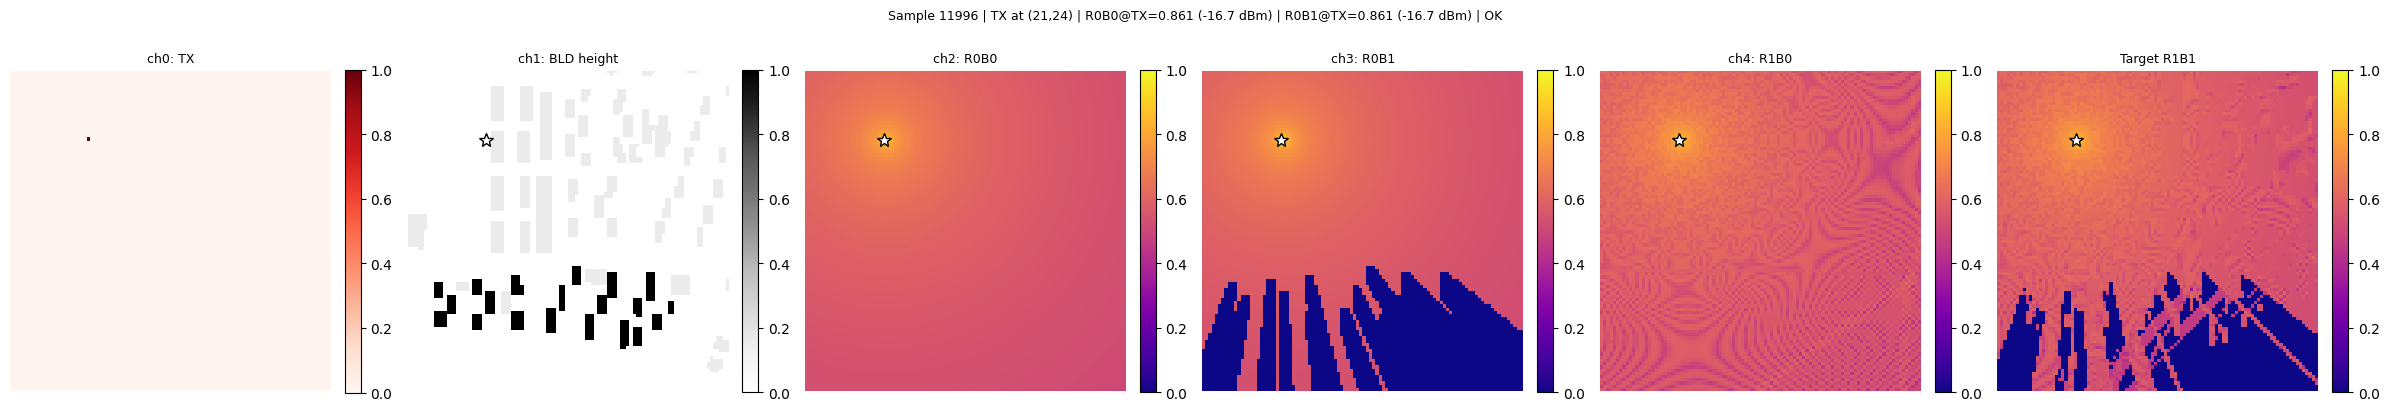

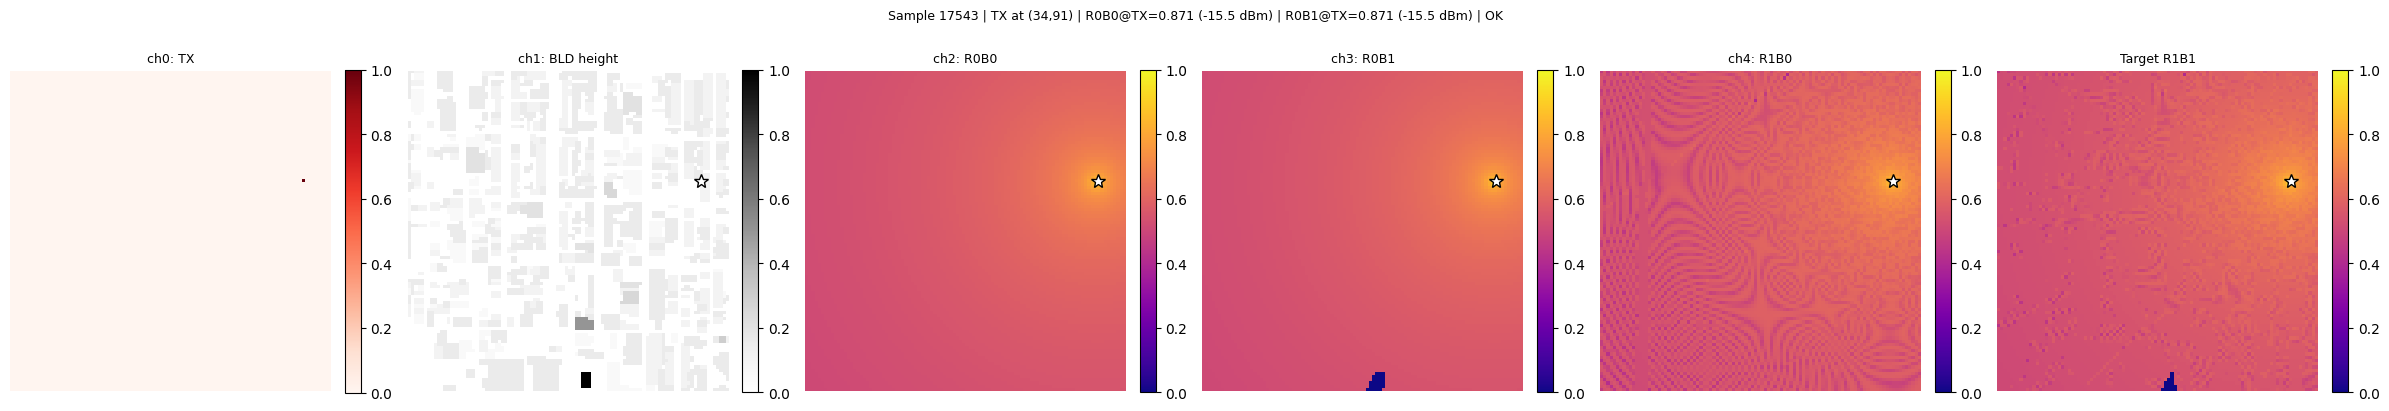

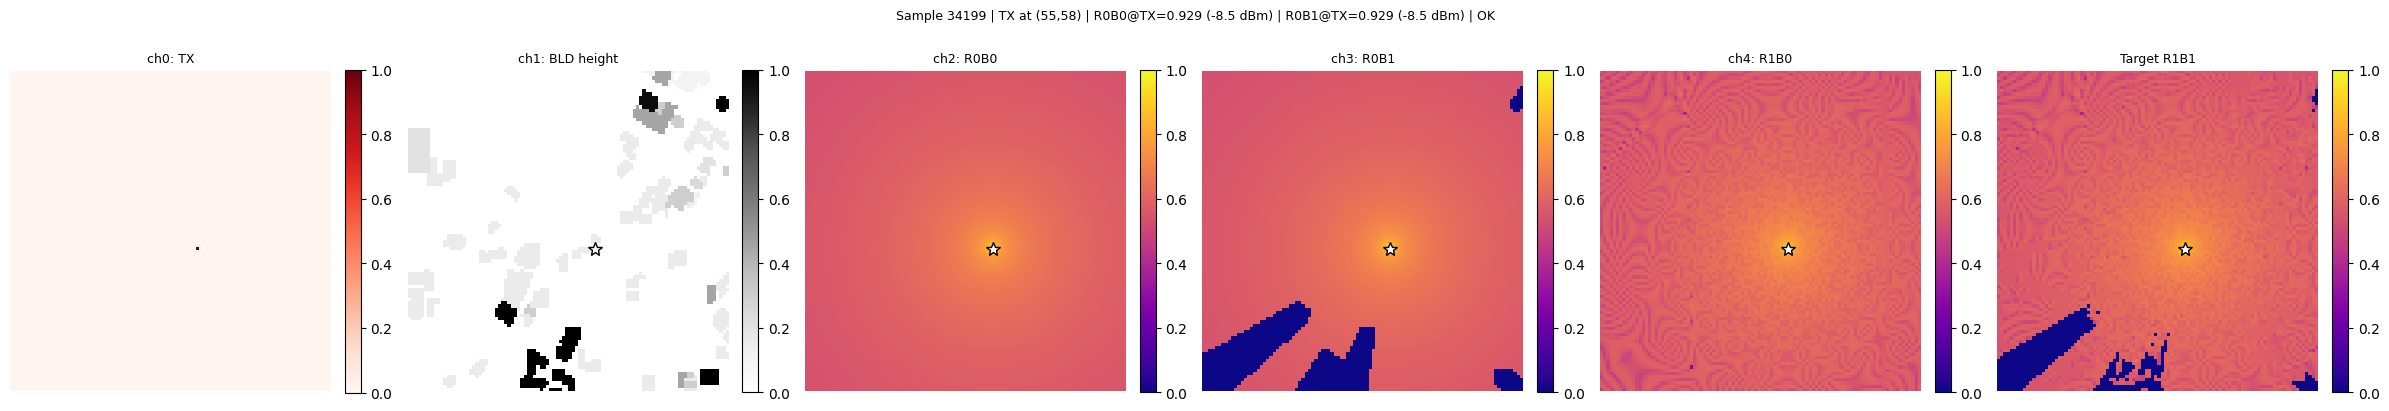

In [ ]:
import random
N_SAMPLES = 3
sample_indices = random.sample(range(len(X_tr_norm)), N_SAMPLES)

for s_idx in sample_indices:
    sample_X = X_tr_norm[s_idx]   # (100, 100, 7)
    sample_Y = Y_tr_norm[s_idx]   # (100, 100, 1)

    ch_tx   = sample_X[..., 0]
    ch_bld  = sample_X[..., 1]
    ch_r0b0 = sample_X[..., 2]
    ch_r0b1 = sample_X[..., 3]
    ch_r1b0 = sample_X[..., 4]
    ch_y    = sample_Y[..., 0]

    tx_pos = np.argwhere(ch_tx > 0.5)

    fig, axes = plt.subplots(1, 6, figsize=(24, 4))   # 6 panels
    channels = [
        (ch_tx,   'ch0: TX',         'Reds'),
        (ch_bld,  'ch1: BLD height', 'Greys'),
        (ch_r0b0, 'ch2: R0B0',       'plasma'),
        (ch_r0b1, 'ch3: R0B1',       'plasma'),
        (ch_r1b0, 'ch4: R1B0',       'plasma'),
        (ch_y,    'Target R1B1',     'plasma'),
    ]
    for ax, (data, title, cmap) in zip(axes, channels):
        im = ax.imshow(data, cmap=cmap, vmin=0, vmax=1, origin='upper')
        ax.set_title(title, fontsize=9)
        ax.axis('off')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        # Overlay TX marker on all channels except TX itself
        if title != 'ch0: TX' and len(tx_pos) > 0:
            r, c = tx_pos[0]
            ax.plot(c, r, 'w*', markersize=10, markeredgecolor='black', lw=0.5)

    if len(tx_pos) > 0:
        r, c = tx_pos[0]
        r0b0_val = ch_r0b0[r, c]
        r0b1_val = ch_r0b1[r, c]
        alignment = 'OK' if r0b0_val > 0.7 else 'CHECK — TX not in high-signal region'
        title_str = (f'Sample {s_idx} | TX at ({r},{c}) | '
                     f'R0B0@TX={r0b0_val:.3f} ({r0b0_val*120-120:.1f} dBm) | '
                     f'R0B1@TX={r0b1_val:.3f} ({r0b1_val*120-120:.1f} dBm) | {alignment}')
    else:
        title_str = f'Sample {s_idx} | TX pixel NOT FOUND'

    plt.suptitle(title_str, fontsize=9, y=1.02)
    plt.tight_layout()
    plt.show()

print('Alignment check complete.')
print('Expect: R0B0 bright at TX; R0B1 darker in building shadows; R1B0 shows reflection patterns.')
print('If TX star appears outside bright R0B0 region, the transpose fix failed.')


## Cell 9 — Build Split Metadata (ROI-level)

Assigns each ROI to exactly one split (train / val / test).
All Tx samples within a ROI land in the same group — no ROI straddles splits.

**Why ROI-level matters:** Sample-level splits can place Tx_1 of an ROI in train
and Tx_2 in val. Since all Txs within a ROI share the same building layout, this
constitutes a mild form of leakage and inflates generalisation metrics.

**Implementation:**
1. `roi_id` and `tx_idx` were recorded per-sample in Cell 4 (no JSON replay).
2. Unique ROIs are split 70/15/15, then the split label is broadcast to all Tx samples.
3. Arrays are re-indexed from the fully-normalised data to match the ROI-level assignment.
4. Integrity check confirms no ROI appears in more than one split.

Saved as `split_metadata_roi_split.csv` — the filename explicitly encodes the split strategy.


In [ ]:
# ── Build metadata DataFrame from records captured at load time ───────────
# roi_id and tx_idx were recorded in Cell 4 — no JSON replay needed.
meta_df = pd.DataFrame(all_meta_records)
n_total = X_tr_norm.shape[0] + X_val_norm.shape[0] + X_test_norm.shape[0]
assert len(meta_df) == n_total, \
    f'Metadata rows {len(meta_df)} != total samples {n_total}'

# ── ROI-level split ────────────────────────────────────────────────────────
# Get unique ROIs and assign each ROI to exactly one split.
# All Tx samples within a ROI land in the same group — no ROI straddles splits.
unique_rois = meta_df[['city', 'roi_id']].drop_duplicates().reset_index(drop=True)
n_rois = len(unique_rois)

# Two-step split on ROI list
roi_tr_val, roi_test = train_test_split(
    unique_rois, test_size=TEST_SIZE, random_state=RANDOM_SEED)
roi_tr, roi_val = train_test_split(
    roi_tr_val, test_size=VAL_SIZE, random_state=RANDOM_SEED)

# Build a lookup: (city, roi_id) → split label
split_lookup = {}
for _, row in roi_tr.iterrows():
    split_lookup[(row['city'], row['roi_id'])] = 'train'
for _, row in roi_val.iterrows():
    split_lookup[(row['city'], row['roi_id'])] = 'val'
for _, row in roi_test.iterrows():
    split_lookup[(row['city'], row['roi_id'])] = 'test'

meta_df['split'] = meta_df.apply(
    lambda r: split_lookup[(r['city'], r['roi_id'])], axis=1)

# ── Verify no ROI straddles splits ────────────────────────────────────────
roi_split_counts = meta_df.groupby(['city', 'roi_id'])['split'].nunique()
assert (roi_split_counts == 1).all(), \
    'BUG: some ROIs appear in more than one split!'
print('ROI-level split integrity: OK — every ROI is in exactly one split.')

# ── Summary tables ─────────────────────────────────────────────────────────
print(f'\nROIs assigned:  {len(roi_tr)} train | {len(roi_val)} val | {len(roi_test)} test  (of {n_rois} total)')
print(f'\nROI count per city per split:')
roi_summary = meta_df.groupby(['city', 'split'])['roi_id'].nunique().unstack(fill_value=0)
roi_summary['total'] = roi_summary.sum(axis=1)
print(roi_summary.to_string())

print('\nSample count per city per split:')
sample_summary = meta_df.groupby(['city', 'split']).size().unstack(fill_value=0)
sample_summary['total'] = sample_summary.sum(axis=1)
print(sample_summary.to_string())

print(f'\nTotal — Train: {(meta_df.split=="train").sum():,}  '
      f'Val: {(meta_df.split=="val").sum():,}  '
      f'Test: {(meta_df.split=="test").sum():,}')

# ── Reorder X/Y arrays to match ROI-level split assignment ────────────────
# The normalized arrays were split sample-by-sample in Cell 5; we need to
# re-derive the index order from the ROI-level assignment.
train_mask = (meta_df['split'] == 'train').values
val_mask   = (meta_df['split'] == 'val').values
test_mask  = (meta_df['split'] == 'test').values

# Reconstruct from the full normalized array
# NOTE: X_tr_norm / X_val_norm / X_test_norm from Cell 5 are sample-level splits
# and their ordering no longer matches meta_df after ROI-level reassignment.
# We need to go back to the pre-split normalized data. Reconstruct from parts:
X_all_norm = np.concatenate([X_tr_norm, X_val_norm, X_test_norm], axis=0)
Y_all_norm = np.concatenate([Y_tr_norm, Y_val_norm, Y_test_norm], axis=0)

# Apply sample-level index reorder from Cell 5's split (to restore original order)
# The split in Cell 5 used: idx_tr_val, idx_test then idx_tr, idx_val.
# Reconstruct the original index permutation used there.
idx_all = np.arange(n_total)
idx_tr_val_c5, idx_test_c5 = train_test_split(
    idx_all, test_size=TEST_SIZE, random_state=RANDOM_SEED)
idx_tr_c5, idx_val_c5 = train_test_split(
    idx_tr_val_c5, test_size=VAL_SIZE, random_state=RANDOM_SEED)
# Reconstruct the order in which Cell 5 stacked: tr, val, test
reorder_inv = np.empty(n_total, dtype=int)
reorder_inv[idx_tr_c5]  = np.arange(len(idx_tr_c5))
reorder_inv[idx_val_c5] = len(idx_tr_c5) + np.arange(len(idx_val_c5))
reorder_inv[idx_test_c5]= len(idx_tr_c5) + len(idx_val_c5) + np.arange(len(idx_test_c5))
# X_all_norm[reorder_inv] restores original load order
X_all_norm = X_all_norm[reorder_inv]
Y_all_norm = Y_all_norm[reorder_inv]

# Now split by ROI mask (aligned with original load order = meta_df order)
X_tr_norm   = X_all_norm[train_mask]
Y_tr_norm   = Y_all_norm[train_mask]
X_val_norm  = X_all_norm[val_mask]
Y_val_norm  = Y_all_norm[val_mask]
X_test_norm = X_all_norm[test_mask]
Y_test_norm = Y_all_norm[test_mask]
del X_all_norm, Y_all_norm
gc.collect()

print(f'\nFinal array shapes (ROI-level split):')
print(f'  X_tr_norm:   {X_tr_norm.shape}')
print(f'  X_val_norm:  {X_val_norm.shape}')
print(f'  X_test_norm: {X_test_norm.shape}')


ROI-level split integrity: OK — every ROI is in exactly one split.

ROIs assigned:  1014 train | 218 val | 218 test  (of 1450 total)

ROI count per city per split:
split      test  train  val  total
city                              
Abu Dhabi     4     30    5     39
Bangkok      18     83   10    111
Beijing      14     70   19    103
Busan        37    153   29    219
Changsha      4     32    7     43
Chicago      11     45    7     63
Dalian        5     12    6     23
Doha          8     13    4     25
Dubai         9     46   13     68
Guangzhou    37    146   23    206
Hangzhou     22     81   16    119
Hefei        12     24    8     44
Hong Kong     7     43   13     63
Houston       5     34    8     47
Incheon       7    119   26    152
Istanbul      8     50   16     74
Jakarta      10     33    8     51

Sample count per city per split:
split      test  train   val  total
city                               
Abu Dhabi   200   1500   250   1950
Bangkok     900   4150   500 

## Cell 10 — Save to Drive

Saves the arrays as uncompressed `.npy` files, plus the split metadata (CSV) and a
config file (JSON).

In [ ]:
import json as _json

print(f'Saving to: {SAVE_DIR}')
print('This will take a few minutes...\n')

t0 = time.time()

np.save(f'{SAVE_DIR}/X_tr_norm.npy',   X_tr_norm)
print(f'  X_tr_norm.npy    saved  ({X_tr_norm.nbytes/1e9:.1f} GB)')

np.save(f'{SAVE_DIR}/Y_tr_norm.npy',   Y_tr_norm)
print(f'  Y_tr_norm.npy    saved  ({Y_tr_norm.nbytes/1e9:.1f} GB)')

np.save(f'{SAVE_DIR}/X_val_norm.npy',  X_val_norm)
print(f'  X_val_norm.npy   saved  ({X_val_norm.nbytes/1e9:.1f} GB)')

np.save(f'{SAVE_DIR}/Y_val_norm.npy',  Y_val_norm)
print(f'  Y_val_norm.npy   saved  ({Y_val_norm.nbytes/1e9:.1f} GB)')

np.save(f'{SAVE_DIR}/X_test_norm.npy', X_test_norm)
print(f'  X_test_norm.npy  saved  ({X_test_norm.nbytes/1e9:.1f} GB)')

np.save(f'{SAVE_DIR}/Y_test_norm.npy', Y_test_norm)
print(f'  Y_test_norm.npy  saved  ({Y_test_norm.nbytes/1e9:.1f} GB)')

# ── Metadata CSV — name encodes split strategy ─────────────────────────────
# 'roi_split' = every ROI belongs to exactly one split group
meta_csv_path = f'{SAVE_DIR}/split_metadata_roi_split.csv'
meta_df.to_csv(meta_csv_path, index=False)
print(f'  split_metadata_roi_split.csv saved ({len(meta_df):,} rows)')
print(f'    Columns: {list(meta_df.columns)}')

# ── Config JSON ────────────────────────────────────────────────────────────
config = {
    'random_seed':   RANDOM_SEED,
    'test_size':     TEST_SIZE,
    'val_size':      VAL_SIZE,
    'phys_min':      PHYS_MIN,
    'phys_max':      PHYS_MAX,
    'range_dbm':     RANGE_DBM,
    'max_height':    MAX_HEIGHT,
    'grid_h':        GRID_H,
    'grid_w':        GRID_W,
    'n_channels':    N_CHANNELS,
    'tx_per_roi':    TX_PER_ROI,
    'total_samples': int(n_total),
    'n_train':       int(X_tr_norm.shape[0]),
    'n_val':         int(X_val_norm.shape[0]),
    'n_test':        int(X_test_norm.shape[0]),
    'split_strategy': 'roi_level',
    'split_metadata_file': 'split_metadata_roi_split.csv',
    'transpose_fix': 'TX(ch0) and BLD(ch1) transposed via np.transpose(axes=(0,2,1))'
}
with open(f'{SAVE_DIR}/config.json', 'w') as f:
    _json.dump(config, f, indent=2)
print(f'  config.json saved')

t1 = time.time()
print(f'\nAll files saved in {(t1-t0)/60:.1f} min')
print(f'\nTraining notebooks can now use the fast load cell.')
print(f'Split strategy: ROI-level — each ROI is in exactly one split.')


## Cell 11 — Verification: Reload and Confirm Integrity

Reloads the saved files and confirms shapes, value ranges, and config match.
Run this to be sure everything saved correctly before using in training.

In [ ]:
import json as _json

print('Verifying saved files...\n')
t0 = time.time()

# Reload config
with open(f'{SAVE_DIR}/config.json') as f:
    cfg = _json.load(f)

# Reload arrays
X_tr_v   = np.load(f'{SAVE_DIR}/X_tr_norm.npy')
Y_tr_v   = np.load(f'{SAVE_DIR}/Y_tr_norm.npy')
X_val_v  = np.load(f'{SAVE_DIR}/X_val_norm.npy')
Y_val_v  = np.load(f'{SAVE_DIR}/Y_val_norm.npy')
X_test_v = np.load(f'{SAVE_DIR}/X_test_norm.npy')
Y_test_v = np.load(f'{SAVE_DIR}/Y_test_norm.npy')
meta_v   = pd.read_csv(f'{SAVE_DIR}/split_metadata_roi_split.csv')

t1 = time.time()
print(f'Reload time: {(t1-t0)/60:.1f} min')
print()

# Shape checks
assert X_tr_v.shape   == X_tr_norm.shape,   'Train X shape mismatch'
assert Y_tr_v.shape   == Y_tr_norm.shape,   'Train Y shape mismatch'
assert X_val_v.shape  == X_val_norm.shape,  'Val X shape mismatch'
assert X_test_v.shape == X_test_norm.shape, 'Test X shape mismatch'

# Value range checks
assert X_tr_v.min() >= -1.0 and X_tr_v.max() <= 1.0, 'X range out of bounds'
assert Y_tr_v.min() >= 0.0  and Y_tr_v.max() <= 1.0, 'Y range out of bounds'

# Config checks
assert cfg['random_seed']    == RANDOM_SEED
assert cfg['phys_min']       == PHYS_MIN
assert cfg['n_channels']     == N_CHANNELS
assert cfg['total_samples']  == n_total
assert cfg['max_height']     == MAX_HEIGHT,  f'MAX_HEIGHT mismatch: {cfg["max_height"]} != {MAX_HEIGHT}'
assert cfg['split_strategy'] == 'roi_level', 'Split strategy not recorded as roi_level'

# Metadata checks
assert len(meta_v) == n_total, f'Metadata rows mismatch'
assert set(meta_v['split'].unique()) == {'train', 'val', 'test'}
assert 'roi_id' in meta_v.columns and 'tx_idx' in meta_v.columns, 'Missing roi_id or tx_idx columns'

# ROI-level integrity check
roi_split_cts = meta_v.groupby(['city', 'roi_id'])['split'].nunique()
assert (roi_split_cts == 1).all(), 'BUG: some ROIs span multiple splits in saved CSV!'
print('ROI-level split integrity: OK')

print('\nAll checks passed:')
print(f'  X_tr_norm  shape: {X_tr_v.shape}   range: [{X_tr_v.min():.4f}, {X_tr_v.max():.4f}]')
print(f'  X_val_norm shape: {X_val_v.shape}')
print(f'  X_test_norm shape:{X_test_v.shape}')
print(f'  Y_tr_norm  range: [{Y_tr_v.min():.4f}, {Y_tr_v.max():.4f}]')
print(f'  MAX_HEIGHT:       {cfg["max_height"]} m  (UAV altitude ceiling)')
print(f'  Split strategy:   {cfg["split_strategy"]}')
print(f'  Metadata:  {len(meta_v):,} rows — columns: {list(meta_v.columns)}')
print(f'  Split counts: {meta_v["split"].value_counts().to_dict()}')
print()
print('Preprocessing complete. Training notebooks can now use the fast load cell.')

del X_tr_v, Y_tr_v, X_val_v, Y_val_v, X_test_v, Y_test_v
gc.collect()
